In [42]:
import sys
import os
import pandas as pd
import numpy as np

sys.path.append(os.path.abspath('..'))

from quinex_application.visualisation.quinex_visualisation import QuinexVisualisation
from quinex_application.postprocessing.data_processing import reference_contains_term

In [43]:
visualisation = QuinexVisualisation()

### **Import Results**

#### **CAPEX**

In [44]:
cost_capex = pd.read_excel("../data/visualisation_files/unit_converted/df_technologies_capex.xlsx")
cost_capex["entity_mapping"].value_counts().head(20)

entity_mapping
PV                      356
Electrolyzer            199
Wind                    184
Bioenergy                63
Offshore Wind            45
Nuclear                  42
Hydrogen                 39
Onshore Wind             26
Battery                  26
Hydropower               26
Geothermal               19
Natural Gas              14
Coal                     12
Lithium-Ion Battery       9
CCS                       7
Green Hydrogen            6
Hybrid Energy System      2
Lead Acid Battery         2
DAC                       1
Name: count, dtype: int64

In [45]:
cost_capex.columns

Index(['Unnamed: 0', 'DOI', 'source_url', 'Abstract', 'publication_year',
       'author_countries', 'entity', 'property', 'quantity_text', 'quote',
       'value_normalized', 'unit_normalized', 'quantity_normalized',
       'temporal_scope', 'spatial_scope', 'unit_dimension', 'references',
       'classification', 'entity_mapping', 'entity_base_mapping',
       'property_mapping', 'property_base_mapping', 'value_converted'],
      dtype='object')

In [46]:
cost_capex[(cost_capex["spatial_scope"].notnull()) & (cost_capex["temporal_scope"].notna()) & (cost_capex["DOI"] == "10.1016/j.renene.2018.09.021")][['DOI', 'entity', 'property', 'temporal_scope', 'spatial_scope', 'value_converted', 'value_normalized', 'unit_normalized', 'classification', 'author_countries', 'quote', 'references']].head(30)

,DOI,entity,property,temporal_scope,spatial_scope,value_converted,value_normalized,unit_normalized,classification,author_countries,quote,references
278,10.1016/j.renene.2018.09.021,Utility-scale solar PV,capex,{'year': 2018.0},"{""text"": ""Mauritius"", ""country"": ""Mauritius"", ""latitude"": -20.3484, ""longitude"": 57.5522}",1.175,1175.0,"[('$', 1.0, 'http://qudt.org/vocab/unit/CCY_USD', None), ('/kW', -1.0, 'http://qudt.org/vocab/unit/KiloW', None)]","{'rational': None, 'system': 'real_world', 'type': None}",['US' 'MU'],NaN,NaN
279,10.1016/j.renene.2018.09.021,onshore wind,local capex,{'year': 2018.0},"{""text"": ""Mauritius"", ""country"": ""Mauritius"", ""latitude"": -20.3484, ""longitude"": 57.5522}",2.251,2251.0,"[('$', 1.0, 'http://qudt.org/vocab/unit/CCY_USD', None), ('/kW', -1.0, 'http://qudt.org/vocab/unit/KiloW', None)]","{'rational': 'individual_literature_sources', 'system': 'real_world', 'type': 'observation'}",['US' 'MU'],NaN,"[{'title': 'Renewable Power Generation Costs in 2017', 'venue': ''}]"
280,10.1016/j.renene.2018.09.021,onshore wind,capital cost,{'year': 2017.0},"{""text"": ""Mauritius"", ""country"": ""Mauritius"", ""latitude"": -20.3484, ""longitude"": 57.5522}",1.500,1500.0,"[('$', 1.0, 'http://qudt.org/vocab/unit/CCY_USD', None), ('/kW', -1.0, 'http://qudt.org/vocab/unit/KiloW', None)]","{'rational': 'individual_literature_sources', 'system': 'real_world', 'type': 'observation'}",['US' 'MU'],NaN,"[{'title': 'Renewable Power Generation Costs in 2017', 'venue': ''}]"


In [47]:
len(cost_capex[cost_capex["references"].apply(lambda ref: reference_contains_term(ref, term="irena"))])

2

In [48]:
# cost_capex['quantity_normalized'] = cost_capex['quantity_normalized'].apply(
#     lambda x: eval(x, {"array": np.array}) if isinstance(x, str) else x
# )
# cost_capex = cost_capex[
#     cost_capex['quantity_normalized'].apply(
#         lambda q: (
#             q.get('type') in ('single_quantity', 'range')
#             and all(qty.get('modifier') in ('=', '~') for qty in q.get('quantities', []))
#         )
#     )
# ]

#### **Lifetime**

In [49]:
lifetime.columns

Index(['DOI', 'source_url', 'Abstract', 'publication_year', 'author_countries',
       'entity', 'property', 'quantity_text', 'quote', 'value_normalized',
       'unit_normalized', 'quantity_normalized', 'temporal_scope',
       'spatial_scope', 'unit_dimension', 'references', 'classification',
       'entity_mapping', 'entity_base_mapping', 'property_mapping',
       'property_base_mapping'],
      dtype='object')

In [50]:
import json
df = pd.read_parquet("../data/visualisation_files/df_technologies.parquet")
lifetime = df[df["property_mapping"] == "Lifetime"]
# print(len(lifetime))
# lifetime = lifetime[lifetime["unit_normalized"].notna()]
# print(len(lifetime))
# lifetime['unit_normalized'] = lifetime['unit_normalized'].apply(
#     lambda x: np.array(json.loads(x)) if isinstance(x, str) else np.array(x) if isinstance(x, list) else x
# )

lifetime = lifetime[lifetime['unit_normalized'].apply(
    lambda lst: len(lst) == 1 and lst[0].get('unit_uri') == 'http://qudt.org/vocab/unit/YR'
)]
lifetime["unit_normalized"].value_counts()

unit_normalized
[{'exponent': 1.0, 'text': 'years', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]         3897
[{'exponent': 1.0, 'text': 'year', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]           650
[{'exponent': 1.0, 'text': 'yr', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]              15
[{'exponent': 1.0, 'text': 'y', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]                6
[{'exponent': 1.0, 'text': 'Years', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]            5
[{'exponent': 1.0, 'text': 'a', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]                4
[{'exponent': 1.0, 'text': '(25) years', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]       1
[{'exponent': 1.0, 'text': '(5) years', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]        1
[{'exponent': 1.0, 'text': '(year)', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]           1
Nam

In [51]:
# lifetime = lifetime[
#     lifetime['quantity_normalized'].apply(
#         lambda q: (
#             q.get('type') in ('single_quantity', 'range')
#             and all(qty.get('modifier') in ('=', '~') for qty in q.get('quantities', []))
#         )
#     )
# ]

#### **Efficiency**

In [52]:
df = pd.read_parquet("../data/visualisation_files/df_technologies.parquet")
efficiency = df[df["property_mapping"] == "Efficiency"]
efficiency = efficiency[efficiency['unit_normalized'].apply(
    lambda lst: len(lst) == 1 and lst[0].get('unit_uri') == 'http://qudt.org/vocab/unit/PERCENT'
)]
efficiency["unit_normalized"].value_counts()

unit_normalized
[{'exponent': 1.0, 'text': '%', 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}]             18158
[{'exponent': 1.0, 'text': 'percent', 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}]          76
[{'exponent': 1.0, 'text': '.%', 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}]                2
[{'exponent': 1.0, 'text': '%*', 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}]                1
[{'exponent': 1.0, 'text': 'percentage', 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}]        1
Name: count, dtype: int64

In [53]:
# efficiency = efficiency[
#     efficiency['quantity_normalized'].apply(
#         lambda q: (
#             q.get('type') in ('single_quantity', 'range')
#             and all(qty.get('modifier') in ('=', '~') for qty in q.get('quantities', []))
#         )
#     )
# ]

#### **Capcity Factor**

In [54]:
df = pd.read_parquet("../data/visualisation_files/df_technologies.parquet")
cap_factor_raw = df[df["property_mapping"] == "Capacity Factor"]
percent = cap_factor_raw[
    cap_factor_raw['unit_normalized'].apply(
        lambda lst: len(lst) == 1 and lst[0].get('unit_uri') == 'http://qudt.org/vocab/unit/PERCENT'
    )
]

unitless = cap_factor_raw[
    cap_factor_raw['unit_normalized'].apply(
        lambda lst: len(lst) == 1 and lst[0].get('unit_uri') == 'http://qudt.org/vocab/unit/UNITLESS'
    )
]

# nur Werte zwischen 0 und 1 behalten
unitless = unitless[unitless['value_normalized'].between(0, 1)]

# auf Prozent skalieren
unitless['value_normalized'] = unitless['value_normalized'] * 100

# zusammenführen
cap_factor = pd.concat([percent, unitless], ignore_index=True)
cap_factor["unit_normalized"].value_counts()

unit_normalized
[{'exponent': 1.0, 'text': '%', 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}]                             1918
[{'exponent': None, 'text': None, 'unit_uri': 'http://qudt.org/vocab/unit/UNITLESS', 'year': None}]                           321
[{'exponent': 1.0, 'text': 'percent', 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}]                         12
[{'exponent': 1.0, 'text': '% (30%)', 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}]                          1
[{'exponent': 1.0, 'text': '% (+15 to -4%, 106 events)', 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}]       1
Name: count, dtype: int64

### **Visualize Results**

In [55]:
cap_factor_dict_pv = {
    "year": list(range(2010, 2025)),
    "value": [15.0, 15.3, 15.1, 16.5, 16.6, 16.5, 16.8, 17.5, 17.9, 17.5, 16.1, 17.2, 16.9, 16.2, 17.4],
    "entity": ["PV"] * 15
}
cap_factor_dict_onshore = {
    "year": list(range(2010, 2025)),
    #"value": [29, 31, 33, 35, 36, 36, 39, 37, 36, 34],
    "value": [27, 27, 28, 28, 29, 29, 31, 33, 35, 36, 36, 39, 37, 36, 34],
    "entity": ["Onshore Wind"] * 15
}
cap_factor_dict_offshore = {
    "year": list(range(2015, 2025)),
    "value": [42, 40, 45, 39, 42, 39, 39, 41, 41, 42],
    # "value": [38, 38, 40, 44, 35, 42, 40, 45, 39, 42, 39, 39, 41, 41, 42],
    "entity": ["Offshore Wind"] * 10
}

cap_factor_additional = pd.concat([pd.DataFrame(cap_factor_dict_pv), pd.DataFrame(cap_factor_dict_onshore), pd.DataFrame(cap_factor_dict_offshore)], ignore_index=True)

In [56]:
capex_dict_pv = {
    "year": list(range(2010, 2025)),
    "value": [5.284, 4.659, 3.537, 3.107, 2.849, 2.140, 1.958, 1.683, 1.438, 1.188, 1.044, 0.973, 0.930, 0.766, 0.691],
    "entity": ["PV"] * 15
}

capex_additional_onshore = {
    "year": list(range(2010, 2025)),
    "value": [2.324, 2.278, 2.165, 2.234, 2.147, 1.956, 1.960, 1.963, 1.865, 1.766, 1.589, 1.506, 1.353, 1.187, 1.041],
    "entity": ["Onshore Wind"] * 15
}

# capex_additional_offshore = {
#     "year": list(range(2010, 2025)),
#     "value": [5.518, 6.343, 5.651, 5.819, 6.247, 6.265, 4.933, 5.531, 4.944, 4.354, 3.87, 3.229, 3.518, 2.867, 2.852],
#     "entity": ["Offshore Wind"] * 15
# }
capex_additional_offshore = {
    "year": list(range(2019, 2025)),
    "value": [4.354, 3.87, 3.229, 3.518, 2.867, 2.852],
    "entity": ["Offshore Wind"] * 6
}

capex_additional = pd.concat([pd.DataFrame(capex_dict_pv), pd.DataFrame(capex_additional_onshore), pd.DataFrame(capex_additional_offshore)], ignore_index=True)

In [57]:
lcoe_dict_pv = {
    "year": list(range(2010, 2025)),
    "value": [0.417, 0.350, 0.260, 0.200, 0.183, 0.135, 0.118, 0.093, 0.079, 0.069, 0.061, 0.055, 0.051, 0.042, 0.043],
    "entity": ["PV"] * 15
}

lcoe_additional_onshore = {
    "year": list(range(2010, 2025)),
    "value": [0.113, 0.107, 0.098, 0.098, 0.088, 0.076, 0.070, 0.066, 0.056, 0.049, 0.041, 0.036, 0.034, 0.033, 0.034],
    "entity": ["Onshore Wind"] * 15
}

lcoe_additional_offshore = {
    "year": list(range(2010, 2025)),
    "value": [0.208, 0.215, 0.185, 0.156, 0.190, 0.155, 0.128, 0.117, 0.114, 0.095, 0.091, 0.082, 0.081, 0.076, 0.079],
    "entity": ["Offshore Wind"] * 15
}

lcoe_additional = pd.concat([pd.DataFrame(lcoe_dict_pv), pd.DataFrame(lcoe_additional_onshore), pd.DataFrame(lcoe_additional_offshore)], ignore_index=True)

817


C:\Users\m.gorres\AppData\Local\Temp\ipykernel_21816\3931370550.py:10: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_sample = df_sample.applymap(
C:\Users\m.gorres\AppData\Local\Temp\ipykernel_21816\3931370550.py:92: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


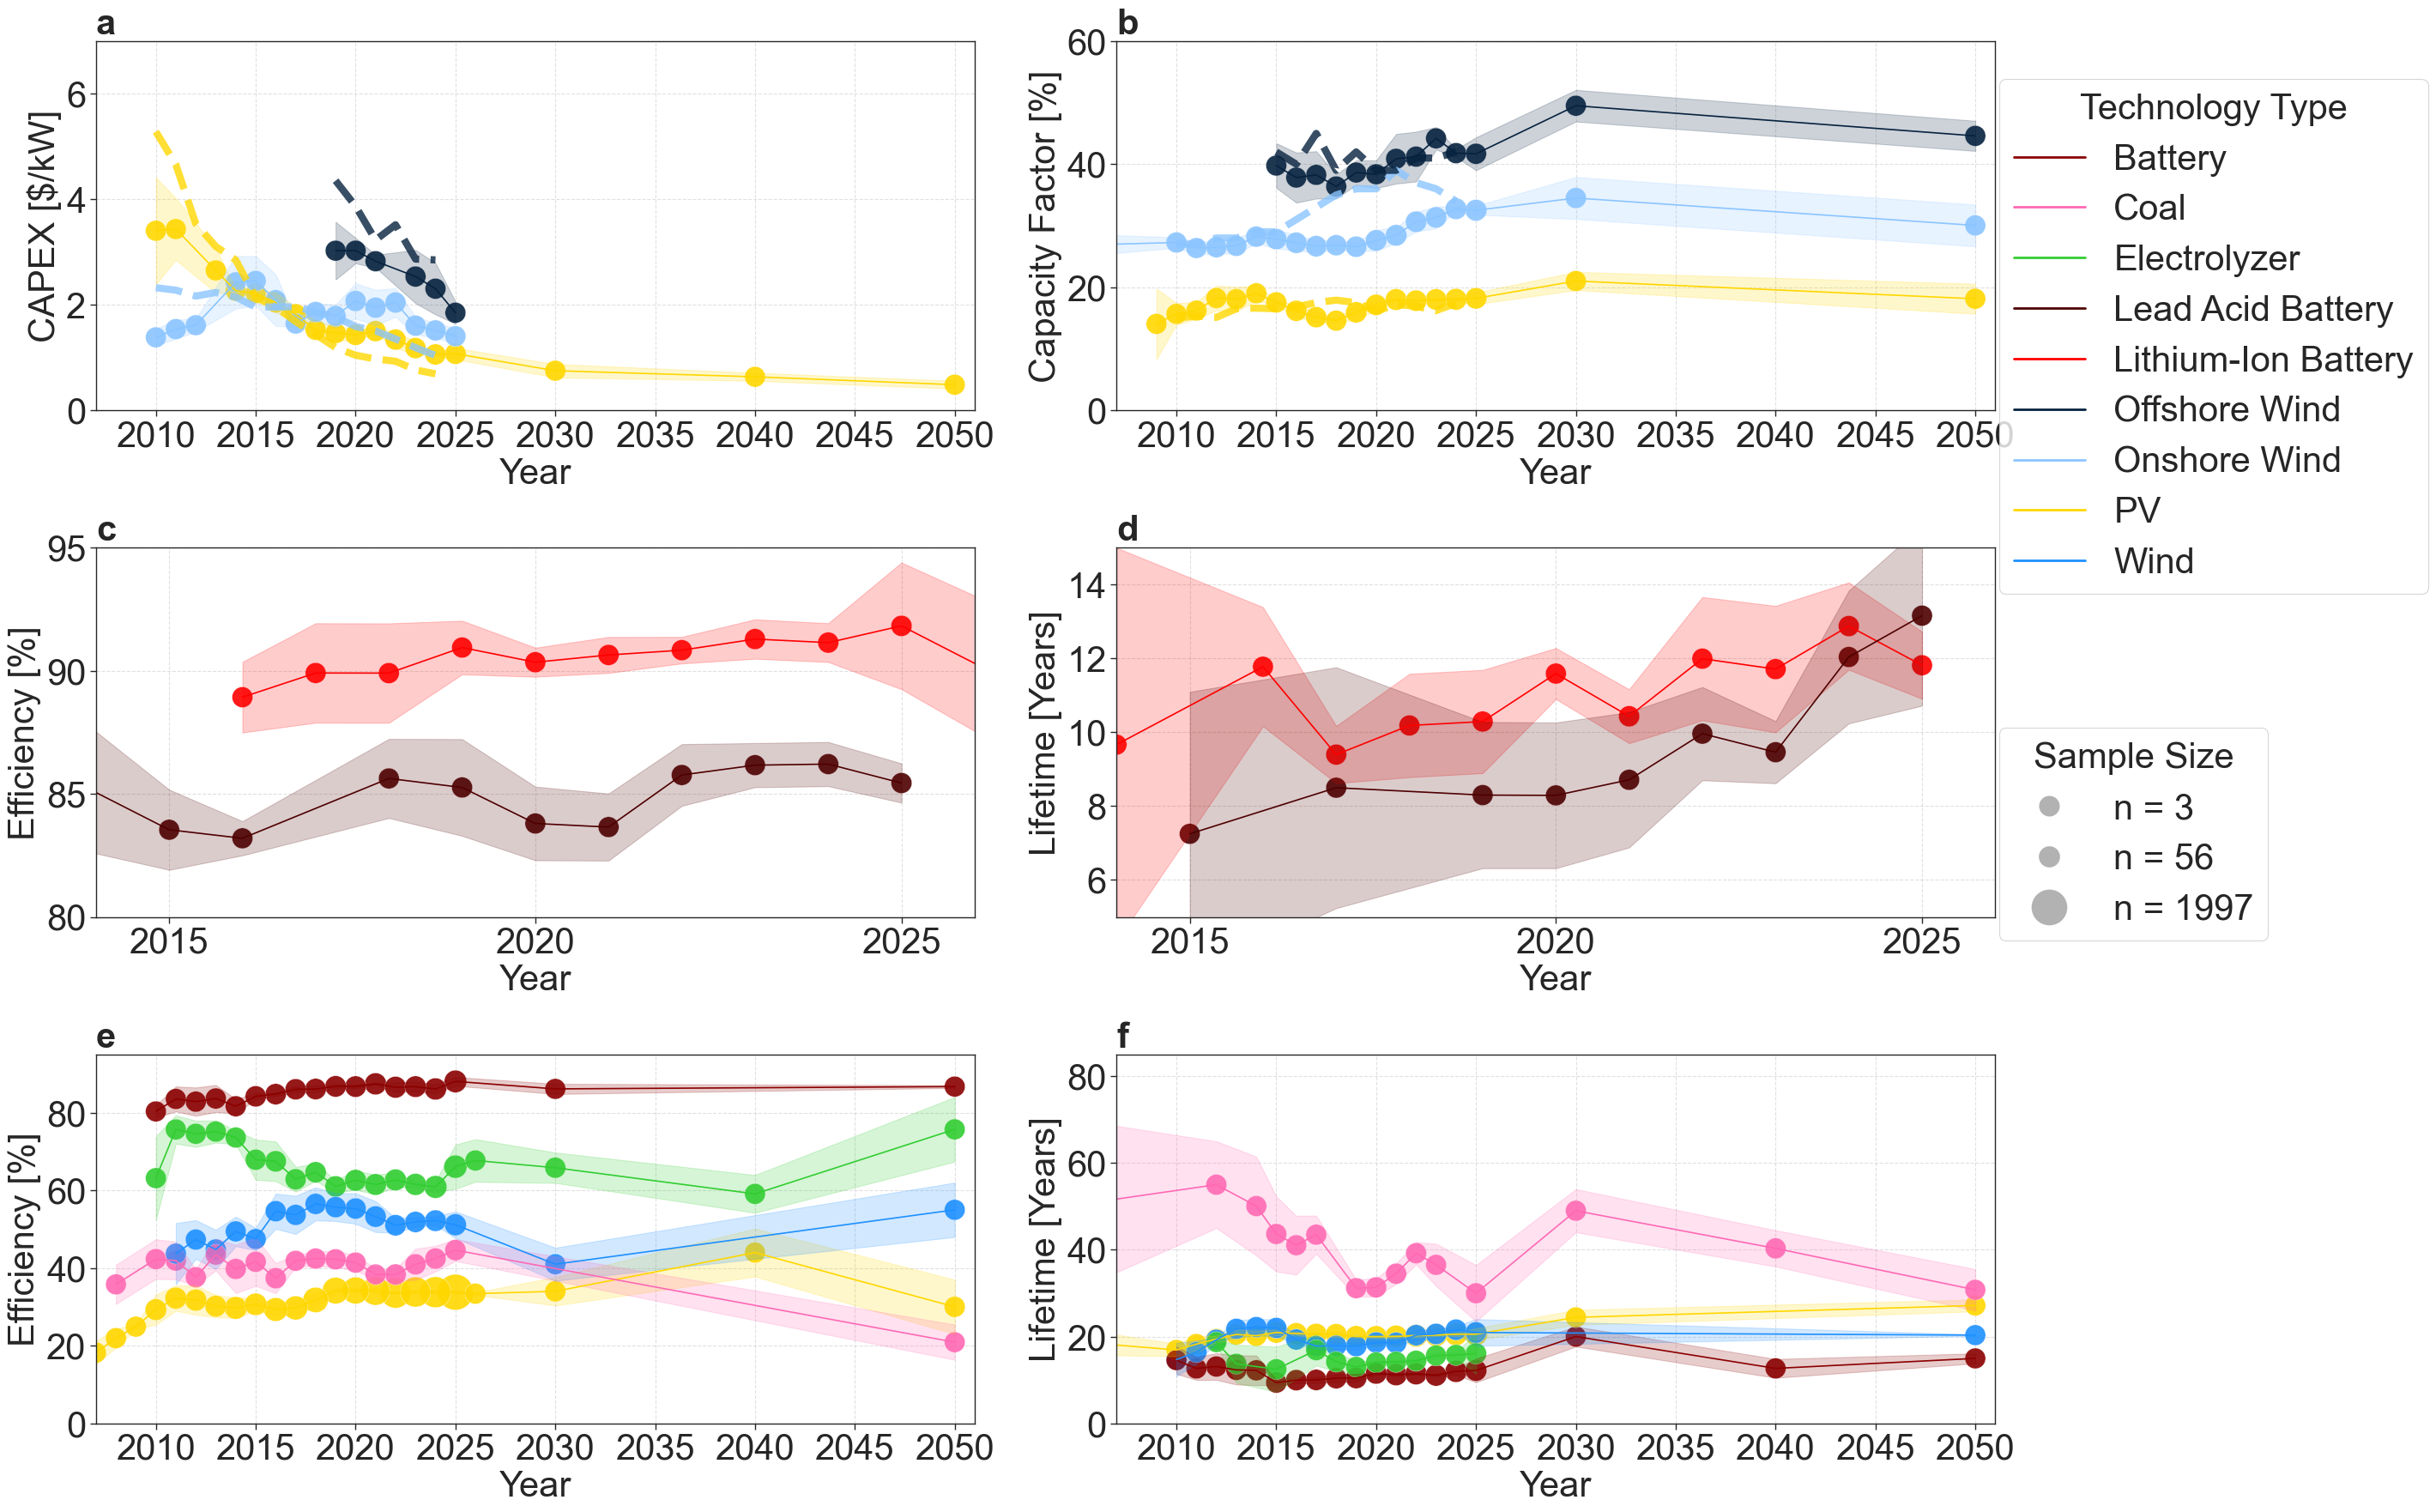

In [66]:
cost_capex['entity_mapping'] = cost_capex['entity_mapping'].replace({
    'Wind': 'Onshore Wind'
})
cap_factor['entity_mapping'] = cap_factor['entity_mapping'].replace({
    'Wind': 'Onshore Wind'
})
print(len(cap_factor[cap_factor["entity_mapping"].isin((['Onshore Wind']))]))

df_sample = cap_factor[cap_factor['entity_mapping'] == 'Onshore Wind'].sample(n=500)
df_sample = df_sample.applymap(
    lambda x: f"'{x}" if isinstance(x, str) and x.startswith('=') else x
)
df_sample.to_csv("capfactor_data_500.csv", index=False, sep=';', decimal=',')


data = [
    {
    'df': cost_capex[cost_capex["entity_mapping"].isin(['PV', 'Offshore Wind', 'Onshore Wind'])],
    'entity_col': 'entity_mapping',
    'value_col': 'value_converted',
    'ylabel': 'CAPEX [$/kW]', 
    'title': 'a',
    'additional_data': capex_additional,
    'year_range': (2007, 2051),
    'y_range': (0, 7),
    },
    {
    'df': cap_factor[cap_factor["entity_mapping"].isin((['PV', 'Offshore Wind', 'Onshore Wind']))],
    'entity_col': 'entity_mapping',
    'value_col': 'value_normalized',
    'ylabel': 'Capacity Factor [%]', 
    'title': 'b',
    'additional_data': cap_factor_additional,
    'year_range': (2007, 2051),
    'y_range': (0, 60),
    },
    {
    'df': efficiency[efficiency["entity_mapping"].isin(['Lithium-Ion Battery', 'Lead Acid Battery'])],
    'entity_col': 'entity_mapping',
    'value_col': 'value_normalized',
    'ylabel': 'Efficiency [%]', 
    'title': 'c',
    'year_range': (2014, 2026),
    'y_range': (80, 95),
    },
    {
    'df': lifetime[lifetime["entity_mapping"].isin(['Lithium-Ion Battery', 'Lead Acid Battery'])],
    'entity_col': 'entity_mapping',
    'value_col': 'value_normalized',
    'ylabel': 'Lifetime [Years]',
    'title': 'd',
    'year_range': (2014, 2026),
    'y_range': (5, 15),
    },
    {
    'df': efficiency[efficiency["entity_base_mapping"].isin(['PV', 'Battery', 'Wind', 'Electrolyzer', 'Coal'])],
    'entity_col': 'entity_base_mapping',
    'value_col': 'value_normalized',
    'ylabel': 'Efficiency [%]', 
    'title': 'e',
    'year_range': (2007, 2051),
    'y_range': (0, 95),
    },
    {
    'df': lifetime[lifetime["entity_base_mapping"].isin(['PV', 'Battery', 'Wind', 'Electrolyzer', 'Coal'])],
    'entity_col': 'entity_base_mapping',
    'value_col': 'value_normalized',
    'ylabel': 'Lifetime [Years]',
    'title': 'f',
    'year_range': (2007, 2051),
    'y_range': (0, 85),
    },
]


fig, data_tables = visualisation.plot_multiple_properties_over_time(
    data_list = data,
    legend_title = 'Technology Type',
    color_dict=visualisation.entity_colors,
    figsize=(24,18),
    legend_position=(0.97,0.95),
    legend_size_position=(0.97,0.53),
    central_tendency="moving average",
    error_type="se",
    error_display="shade",
    font_size=30,
    point_size_range=(300, 900),
    min_papers_per_year=3,
    min_datapoints_per_year=3,
    )

fig.show()
#fig.savefig("../data/figures/results/temporal/technologies_hub_rotor.pdf", bbox_inches='tight')

In [59]:
data_tables['b'][data_tables['b']["entity_mapping"] == "Offshore Wind"].sort_values("jahr")

,jahr,entity_mapping,value_normalized,value_central,n,std_dev,n_window,se
29,2015,Offshore Wind,33.375000,39.775000,4.0,6.290519,3.0,3.631833
30,2016,Offshore Wind,45.950000,37.819444,3.0,7.051469,3.0,4.071168
31,2017,Offshore Wind,34.133333,38.261111,3.0,6.664798,3.0,3.847923
32,2018,Offshore Wind,34.700000,36.377778,5.0,3.408540,3.0,1.967922
33,2019,Offshore Wind,40.300000,38.644444,5.0,3.430635,3.0,1.980678
34,2020,Offshore Wind,40.933333,38.363492,6.0,3.915439,3.0,2.260580
35,2021,Offshore Wind,33.857143,40.873492,7.0,6.986621,3.0,4.033727
36,2022,Offshore Wind,47.830000,41.229048,7.0,7.018259,3.0,4.051994
37,2023,Offshore Wind,42.000000,44.198095,5.0,3.168451,3.0,1.829306
38,2024,Offshore Wind,42.764286,41.793474,14.0,1.088865,3.0,0.628656


### **Investige Results**

In [60]:
cap_factor["entity_mapping"].value_counts()

entity_mapping
Onshore Wind                   817
PV                             689
Electrolyzer                   170
Offshore Wind                  102
Nuclear                         96
Coal                            68
Hydropower                      57
Bioenergy                       47
Hydrogen                        46
Geothermal                      37
CCS                             31
Natural Gas                     31
Battery                         28
DAC                             16
Green Hydrogen                   6
BECCS                            5
Hybrid Energy System             5
Liquefied Natural Gas (LNG)      1
Lead Acid Battery                1
Name: count, dtype: int64

In [61]:
cap_factor_investigation = cap_factor.copy()
cap_factor_investigation = cap_factor_investigation[cap_factor_investigation["entity_mapping"] == "Onshore Wind"]

In [62]:
cap_factor_countries = cap_factor_investigation.explode("author_countries")
cap_factor_countries["entity_mapping"] = cap_factor_countries["author_countries"]
cap_factor_countries[cap_factor_countries["value_normalized"] > 15]["author_countries"].value_counts().head(20)

author_countries
GB    98
US    91
DE    54
CA    41
DK    39
IN    35
CN    32
SE    30
ES    21
PT    21
AU    20
FR    20
NO    18
NL    17
MY    16
IT    15
PL    15
TR    15
FI    14
CO    13
Name: count, dtype: int64

In [63]:
# cap_factor_countries = visualisation.convert_spatial(cap_factor_countries, spatial_col="spatial_scope_refined")
# regions = {
#     "North America": [
#         "United States", "USA", "US",
#         "Canada", "CA"
#     ],
    
#     "Latin America & Caribbean": [
#         "Mexico", "Colombia", "Ecuador",
#         "Chile", "Venezuela", "Brazil",
#         "Caribbean"
#     ],
    
#     "Europe": [
#         "United Kingdom", "UK",
#         "Germany", "Spain", "Poland",
#         "Ireland", "Italy", "Finland",
#         "Sweden", "Denmark", "Portugal",
#         "France", "Estonia", "Netherlands",
#         "Iceland", "Norway", "Faroe Islands",
#         "Croatia", "Albania", "Ukraine"
#     ],
    
#     "Sub-Saharan Africa": [
#         "South Africa", "SA",
#         "Kenya", "Ghana", "Mauritius",
#         "Togo", "Cameroon", "Senegal",
#         "Sierra Leone"
#     ],
    
#     "Middle East & North Africa (MENA)": [
#         "Morocco", "Algeria", "Saudi Arabia",
#         "Iraq", "Iran", "Jordan", "Yemen",
#         "Tunisia", "United Arab Emirates",
#         "Mauritania", "TD" 
#     ],
    
#     "South and East Asia": [
#         "India", "Pakistan", "China", "Japan", "Mongolia",
#         "Philippines", "Australia"
#     ],
    
#     # "East Asia & Pacific": [
#     #     "China", "Japan", "Mongolia",
#     #     "Philippines", "Australia"
#     # ]
# }

# region_map = {
#     country: region
#     for region, countries in regions.items()
#     for country in countries
# }

# cap_factor_countries["region"] = cap_factor_countries["country"].map(region_map)
# cap_factor_countries["entity_mapping"] = cap_factor_countries["region"]
# cap_factor_countries["region"].value_counts()

C:\Users\m.gorres\AppData\Local\Temp\ipykernel_21816\839182815.py:41: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


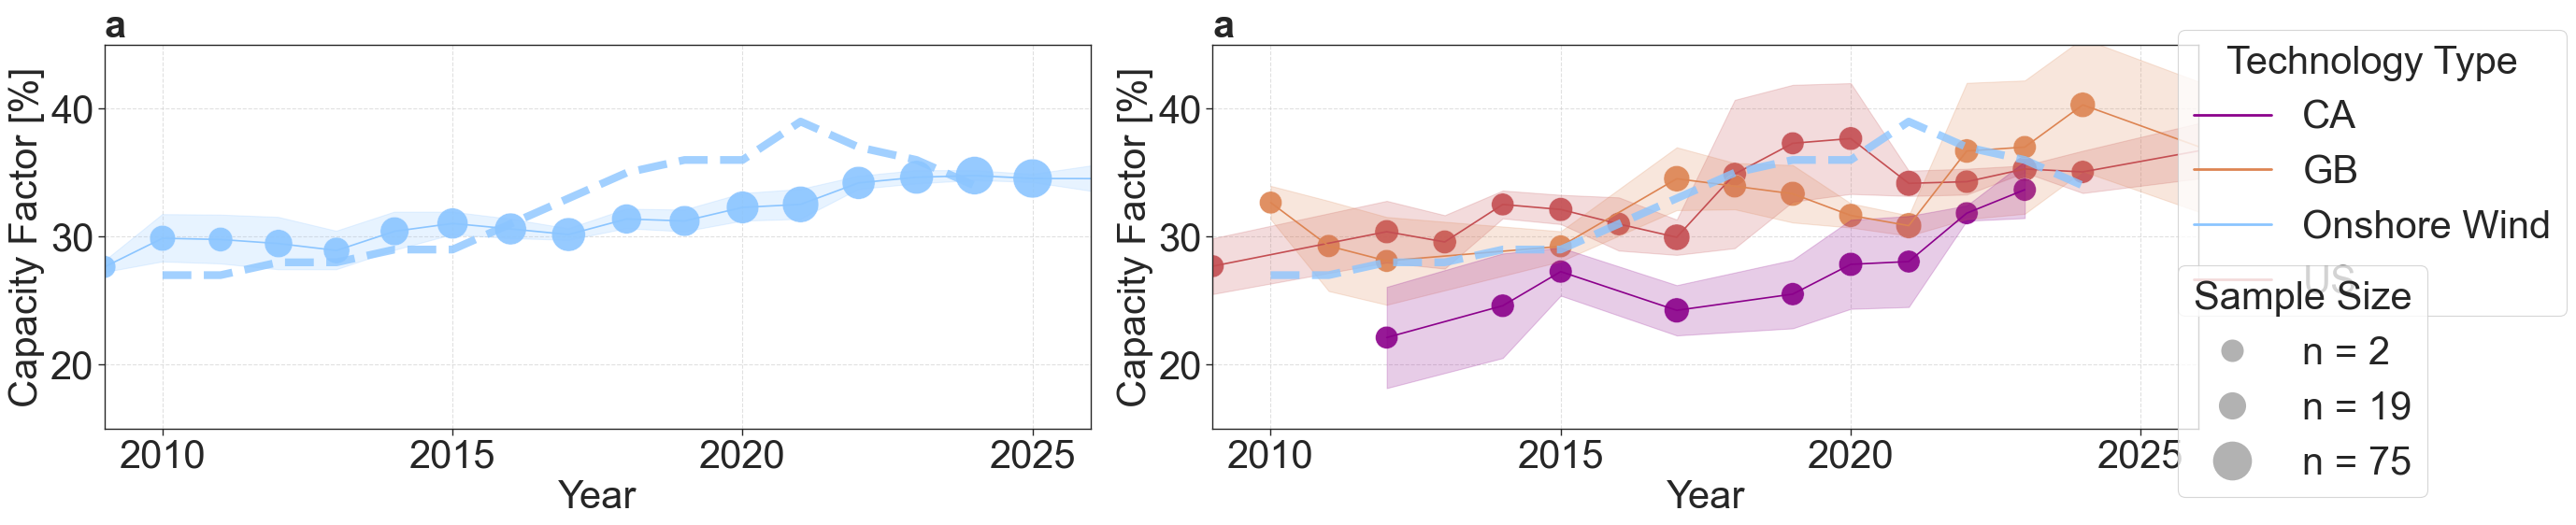

In [64]:


data = [
    {
    'df': cap_factor_investigation[cap_factor_investigation["value_normalized"] > 15],
    'entity_col': 'entity_mapping',
    'value_col': 'value_normalized',
    'ylabel': 'Capacity Factor [%]',
    'title': 'a',
    'additional_data': cap_factor_additional[cap_factor_additional["entity"] == "Onshore Wind"],
    'year_range': (2009, 2026),
    'y_range': (15, 45),
    },
    {
    'df': cap_factor_countries[(cap_factor_countries["author_countries"].isin(["GB", "US", "CA"])) & (cap_factor_countries["value_normalized"] > 15)],
    'entity_col': 'entity_mapping',
    'value_col': 'value_normalized',
    'ylabel': 'Capacity Factor [%]',
    'title': 'a',
    'additional_data': cap_factor_additional[cap_factor_additional["entity"] == "Onshore Wind"],
    'year_range': (2009, 2026),
    'y_range': (15, 45),
    }
]


fig, data_tables = visualisation.plot_multiple_properties_over_time(
    data_list = data,
    legend_title = 'Technology Type',
    color_dict=visualisation.entity_colors,
    figsize=(24,6),
    legend_position=(0.97,0.95),
    legend_size_position=(0.97,0.53),
    central_tendency="moving average",
    error_type="se",
    error_display="shade",
    font_size=30,
    point_size_range=(300, 900),
    min_papers_per_year=2,
    min_datapoints_per_year=2,
    )

fig.show()
fig.savefig("../data/figures/results/temporal/capacity_factor_onshore_wind_country.pdf", bbox_inches='tight')